# Willett Handwriting Dataset

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/chesteklab/neural-decoding-workshop/blob/main/curriculum/dataset-materials/willet-handwriting/willett-handwriting-dataset.ipynb)

In this tutorial we explore the dataset from the landmark paper
[High-performance brain-to-text communication via handwriting](https://doi.org/10.1038/s41586-021-03506-2) (Willett et al., *Nature* 2021).

The data were recorded from participant **T5** as part of the [BrainGate](https://www.braingate.org/) clinical trial.
T5 has a high-level spinal cord injury and is paralyzed from the neck down. Two small electrode arrays were
implanted in the "hand knob" area of his motor cortex, the part of the brain that normally controls the hand.
T5 was asked to *attempt* to handwrite letters as if he were holding a pen. Even though his hand did not move,
the neural activity for handwriting was still there, years after his injury. It was so clear that the
authors could decode what he was writing at about 90 characters per minute.

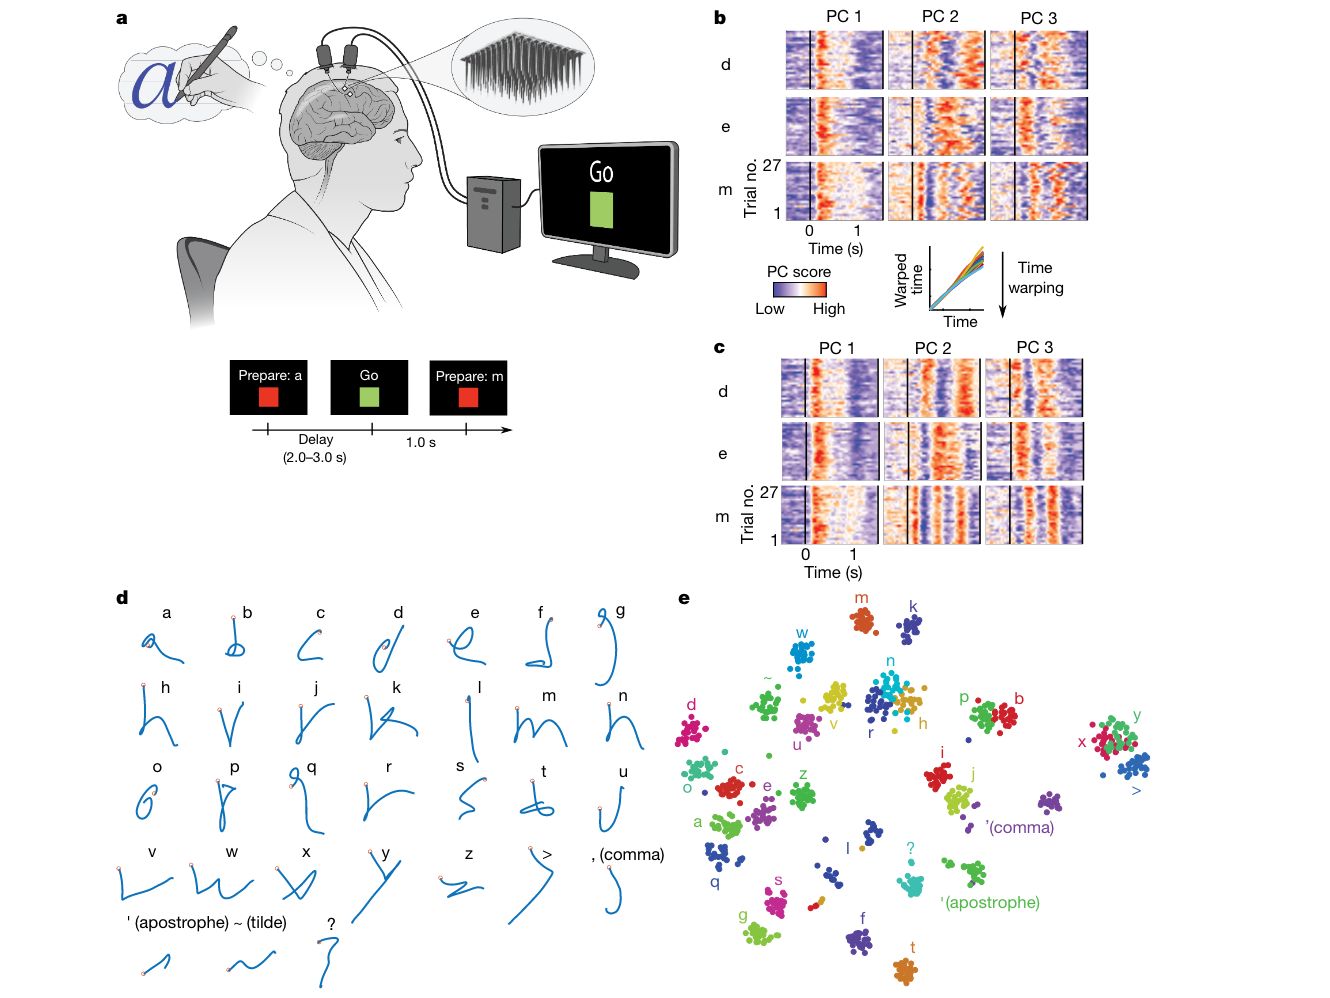

### What you will learn

By the end of this notebook you will be able to:

1. Describe how the data were collected and how they are organized: trials × time × electrodes.
2. Plot spike rasters and firing rates for single electrodes.
3. Explain *why* and *how* we normalize and smooth neural data.
4. Use **PCA** to summarize the activity of 192 electrodes with a handful of dimensions.
5. Understand **time warping**, and why trial-to-trial differences in writing speed matter.
6. Visualize **neural trajectories** and a **t-SNE** map of all the characters.
7. Build a simple **decoder** (k-nearest neighbours) that guesses which character T5 was writing, at about 94% accuracy.

### Data you need

Only two files are needed. Both come from the public [Dryad dataset](https://doi.org/10.5061/dryad.wh70rxwmv) (session `t5.2019.05.08`):

| File | What it contains |
|---|---|
| `t5.2019.05.08_singleLetters.mat` | Raw binned spike counts for every single-character trial |
| `t5.2019.05.08_warpedCubes.mat` | The same trials after normalization and **time warping** (made by the authors) |

## 1. Setup

### 1.1 Import packages

In [1]:
from pathlib import Path

import numpy as np
import scipy.io
from scipy.ndimage import gaussian_filter1d
from scipy.spatial.distance import cdist
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# Make the figures a little nicer to look at
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.family": "STIXGeneral"})

### 1.2 Get the data

Download the two `.mat` files from the workshop's [Figshare dataset](https://figshare.com/s/cab0a41bbfd077732d5d) and put them in the same folder as this notebook.
The cell below checks that both files are there.

In [2]:
DATA_DIR = Path(".")
FIGSHARE_URL = "https://figshare.com/s/cab0a41bbfd077732d5d"

for file_name in ["t5.2019.05.08_singleLetters.mat", "t5.2019.05.08_warpedCubes.mat"]:
    path = DATA_DIR / file_name
    if path.exists():
        print(f"Found {path}")
    else:
        raise FileNotFoundError(f"{path} is missing. Download it from {FIGSHARE_URL} and put it next to this notebook.")

Found t5.2019.05.08_singleLetters.mat
Found t5.2019.05.08_warpedCubes.mat


## 2. Meet the dataset

### 2.1 What is inside `t5.2019.05.08_singleLetters.mat`?

`.mat` files are MATLAB files. `scipy.io.loadmat` reads them into a Python dictionary of NumPy arrays.

In [3]:
dat = scipy.io.loadmat(DATA_DIR / "t5.2019.05.08_singleLetters.mat")

cube_names = [k for k in dat if k.startswith("neuralActivityCube_")]
other_names = [k for k in dat if not k.startswith("__") and k not in cube_names]

print(f"{len(cube_names)} 'neuralActivityCube_<character>' arrays, each of shape {dat[cube_names[0]].shape}\n")
print(f"{'variable':28s} {'shape':16s} dtype")
print("-" * 52)
for name in other_names:
    print(f"{name:28s} {str(dat[name].shape):16s} {dat[name].dtype}")

32 'neuralActivityCube_<character>' arrays, each of shape (27, 201, 192)

variable                     shape            dtype
----------------------------------------------------
neuralActivityTimeSeries     (336932, 192)    uint8
clockTimeSeries              (336932, 1)      float64
blockNumsTimeSeries          (336932, 1)      uint8
blockList                    (9, 1)           uint8
blockStartDates              (9, 1)           object
goPeriodOnsetTimeBin         (864, 1)         int32
delayPeriodOnsetTimeBin      (864, 1)         int32
characterCues                (864, 1)         object
meansPerBlock                (9, 192)         float64
stdAcrossAllData             (1, 192)         float64
arrayGeometryMap             (10, 10)         int32


Here is what the most important variables mean:

| Variable | Meaning |
|---|---|
| `neuralActivityCube_<x>` | Neural activity for character `<x>`: **27 trials × 201 time bins × 192 electrodes** |
| `neuralActivityTimeSeries` | The whole session as one long recording: time bins × 192 electrodes |
| `characterCues` | Which character was shown on each trial, in the order the trials happened |
| `goPeriodOnsetTimeBin` / `delayPeriodOnsetTimeBin` | When the go cue / delay period started on each trial (index into the time series) |
| `blockNumsTimeSeries`, `blockList` | The session was split into 9 recording *blocks*; these say which block each time bin belongs to |
| `meansPerBlock`, `stdAcrossAllData` | Pre-computed mean (per block) and standard deviation of each electrode, used for normalization |

**What is a "spike count" here?** Each number is how many times the voltage on an electrode crossed a threshold
(−3.5 × RMS) during a **10 ms bin**. Each crossing is roughly one action potential (spike).
An electrode can pick up several nearby neurons, so we say **electrodes** (or channels), not *neurons*.
The 192 electrodes come from two 96-channel *Utah arrays*: channels 0–95 are array 1 and 96–191 are array 2.

### 2.2 The task: an "instructed delay" paradigm

Each trial went like this:

```
   |---- delay period (1.5–3 s)----|---- go period (1 s) ----|
   character appears on screen       square turns green (GO):
   above a red square: T5 gets       T5 attempts to write
   ready to write it                 the character
```
(Also refer to the figure at the beginning of the notebook.)

The cubes are aligned to the **go cue**. Each trial covers 2 s: **500 ms before** to **1500 ms after** the go cue.

Total trials: 864
First 10 cues: ['r', 'f', 'greaterThan', 'c', 'z', 'comma', 'i', 'o', 'g', 't']
Each trial window spans -500 ms to 1500 ms around the go cue


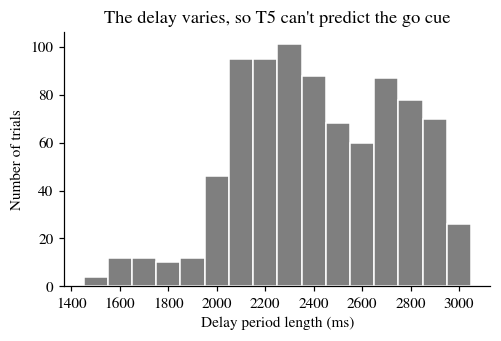

In [4]:
BIN_MS = 10                      # each time bin is 10 ms
GO_IDX = 50                      # index of the go cue inside each 201-bin trial
                                 # (the readme says "time step 51" because MATLAB counts from 1)
t_ms = (np.arange(201) - GO_IDX) * BIN_MS   # time of every bin relative to the go cue

cues = np.array([c[0] for c in dat["characterCues"][:, 0]])
go_bin = dat["goPeriodOnsetTimeBin"][:, 0] - 1      # MATLAB counts from 1, Python from 0
delay_bin = dat["delayPeriodOnsetTimeBin"][:, 0] - 1
delay_ms = (go_bin - delay_bin) * BIN_MS

print(f"Total trials: {len(cues)}")
print(f"First 10 cues: {list(cues[:10])}")
print(f"Each trial window spans {t_ms[0]} ms to {t_ms[-1]} ms around the go cue")

fig, ax = plt.subplots(figsize=(5, 3))
ax.hist(delay_ms, bins=np.arange(1450, 3101, 100), color="tab:gray", edgecolor="white")
ax.set_xlabel("Delay period length (ms)")
ax.set_ylabel("Number of trials")
ax.set_title("The delay varies, so T5 can't predict the go cue")
plt.show()

### 2.3 The 31 characters

T5 wrote the 26 lowercase letters plus 5 punctuation symbols. Two symbols are special:
T5 wrote **`>` to mean a space** and **`~` to mean a period**.
There is also a `doNothing` condition (T5 rests), which we leave out.

Let's stack all characters into one 4-D array:

`raw[character, trial, time, electrode]` → shape **(31, 27, 201, 192)**

In [5]:
CHARS = ["a", "b", "c", "d", "e", "f", "g", "h", "i", "j", "k", "l", "m",
         "n", "o", "p", "q", "r", "s", "t", "u", "v", "w", "x", "y", "z",
         "greaterThan", "comma", "apostrophe", "tilde", "questionMark"]

# How each character is printed on plots
SYMBOL = {c: c for c in CHARS}
SYMBOL.update({"greaterThan": ">", "comma": ",", "apostrophe": "'", "tilde": "~", "questionMark": "?"})

# Colours used in Fig. 1 of the paper (one per character)
COLORS = np.array([[0.3613, 0.8000, 0], [0.8000, 0, 0.1548], [0.8000, 0.1548, 0], [0.8000, 0, 0.4645],
                   [0.6710, 0, 0.8000], [0.3613, 0, 0.8000], [0.5161, 0.8000, 0], [0.8000, 0.6194, 0],
                   [0.8000, 0, 0], [0.6710, 0.8000, 0], [0.2065, 0, 0.8000], [0, 0.1032, 0.8000],
                   [0.8000, 0.3097, 0], [0, 0.7226, 0.8000], [0, 0.8000, 0.5677], [0, 0.8000, 0.2581],
                   [0, 0.2581, 0.8000], [0.0516, 0, 0.8000], [0.8000, 0, 0.6194], [0.8000, 0.4645, 0],
                   [0.8000, 0, 0.7742], [0.8000, 0.7742, 0], [0, 0.5677, 0.8000], [0.8000, 0, 0.3097],
                   [0, 0.8000, 0.4129], [0.0516, 0.8000, 0], [0, 0.4129, 0.8000], [0.5161, 0, 0.8000],
                   [0.2065, 0.8000, 0], [0, 0.8000, 0.1032], [0, 0.8000, 0.7226]])

raw = np.stack([dat["neuralActivityCube_" + c] for c in CHARS]).astype(float)
n_chars, n_trials, n_time, n_elec = raw.shape
print(f"raw.shape = {raw.shape}  ->  {n_chars} characters x {n_trials} trials x "
      f"{n_time} time bins x {n_elec} electrodes")
print(f"Spike counts per bin range from {raw.min():.0f} to {raw.max():.0f}")

raw.shape = (31, 27, 201, 192)  ->  31 characters x 27 trials x 201 time bins x 192 electrodes
Spike counts per bin range from 0 to 8


## 3. Look at the raw activity

### 3.1 Spike rasters and firing rates of one electrode

A **raster plot** puts a tick wherever an electrode recorded a spike. Each row is one trial.
Below each raster we plot the **firing rate** averaged over the 27 trials (a *PSTH*, peri-stimulus time histogram).

To get a nice example, we pick the electrode whose average response differs most between characters,
relative to how noisy it is. Spike-count noise grows with the baseline firing rate, so we divide by √(baseline rate).

In [6]:
EXAMPLE_CHARS = ["d", "e", "m"]
example_idx = [CHARS.index(c) for c in EXAMPLE_CHARS]

# Trial-averaged firing rate in Hz (count per 10 ms bin x 100)
rate_hz = raw.mean(axis=1) * (1000 / BIN_MS)            # (31 chars, 201 time, 192 electrodes)
# How much does each electrode's response differ between characters during the go period?
go_period = (t_ms >= 0) & (t_ms < 1000)
char_selectivity = rate_hz[:, go_period, :].std(axis=0).mean(axis=0)
baseline_hz = rate_hz[:, t_ms < 0, :].mean(axis=(0, 1))          # rate before the go cue
ELECTRODE = int(np.argmax(char_selectivity / np.sqrt(baseline_hz + 1)))
print(f"Example electrode: {ELECTRODE} (array {1 if ELECTRODE < 96 else 2}), "
      f"baseline rate {baseline_hz[ELECTRODE]:.0f} Hz")

Example electrode: 22 (array 1), baseline rate 35 Hz


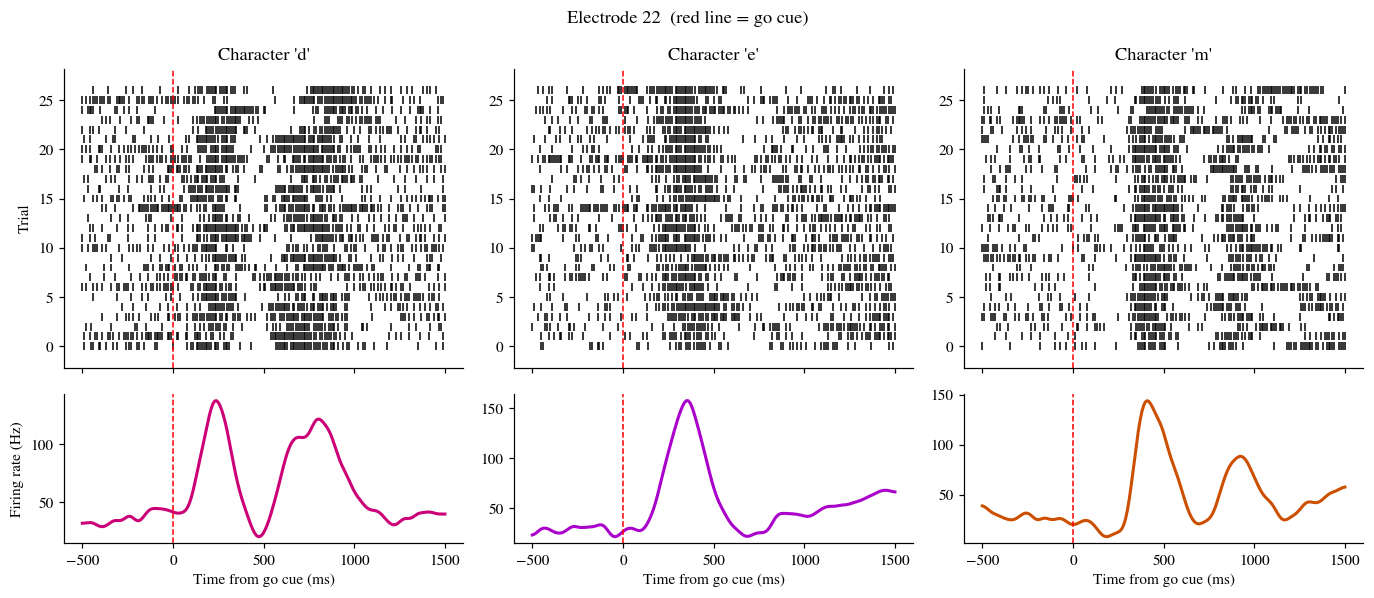

In [7]:
def plot_raster_and_psth(chars, electrode):
    """Raster (top row) and smoothed trial-averaged firing rate (bottom row) for one electrode."""
    fig, axes = plt.subplots(2, len(chars), figsize=(4.2 * len(chars), 5.5),
                             sharex=True, gridspec_kw={"height_ratios": [2, 1]})
    for col, c in enumerate(chars):
        counts = raw[CHARS.index(c), :, :, electrode]          # (27 trials, 201 time)
        spike_times = [t_ms[trial > 0] for trial in counts]    # times of bins with >= 1 spike
        axes[0, col].eventplot(spike_times, colors="black", linelengths=0.8, linewidths=1)
        axes[0, col].set_title(f"Character '{SYMBOL[c]}'")

        rate = gaussian_filter1d(counts.mean(axis=0) * (1000 / BIN_MS), sigma=3)
        axes[1, col].plot(t_ms, rate, color=COLORS[CHARS.index(c)], lw=2)
        axes[1, col].set_xlabel("Time from go cue (ms)")
        for row in range(2):
            axes[row, col].axvline(0, color="r", ls="--", lw=1)
    axes[0, 0].set_ylabel("Trial")
    axes[1, 0].set_ylabel("Firing rate (Hz)")
    fig.suptitle(f"Electrode {electrode}  (red line = go cue)")
    plt.tight_layout()
    plt.show()

plot_raster_and_psth(EXAMPLE_CHARS, ELECTRODE)

**What do you notice?**
- Activity changes after the go cue, about when T5 starts trying to write.
- The response *pattern* differs between characters. Information about *what* is being written is in this electrode!
- Single trials are **noisy**: the ticks look random from trial to trial. Averaging over trials reveals the pattern.

> **Try it:** Change `EXAMPLE_CHARS` or pick a random electrode (e.g. `plot_raster_and_psth(["o", "x"], 10)`). Do all electrodes care about handwriting?

## 4. Preprocessing

Raw spike counts have two problems:

1. **Drift:** an electrode's baseline firing rate slowly changes over the session (the array moves slightly, neurons change).
2. **Different scales:** some electrodes fire at 100 Hz, others at 2 Hz. Without rescaling, the busy electrodes would dominate every analysis.

### 4.1 Block-wise z-scoring

The session had 9 recording blocks. For each trial we subtract the electrode's mean **from that trial's block**,
then divide by the electrode's standard deviation. Let's first see the drift:

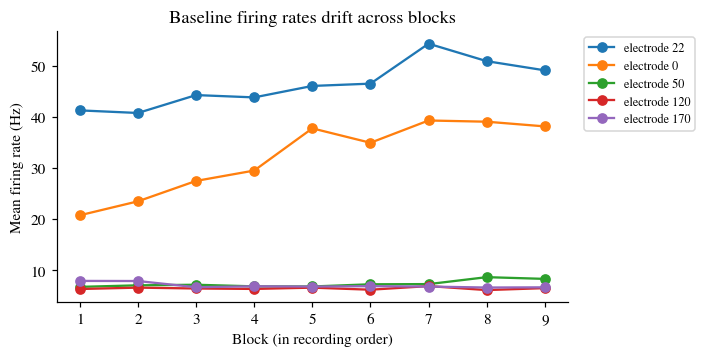

In [8]:
block_list = dat["blockList"][:, 0]
means_per_block = dat["meansPerBlock"]          # (9 blocks, 192 electrodes), spikes per bin
std_all = dat["stdAcrossAllData"][0]            # (192,)

fig, ax = plt.subplots(figsize=(6, 3.2))
for e in [ELECTRODE, 0, 50, 120, 170]:
    ax.plot(range(1, 10), means_per_block[:, e] * (1000 / BIN_MS), "o-", label=f"electrode {e}")
ax.set_xlabel("Block (in recording order)")
ax.set_ylabel("Mean firing rate (Hz)")
ax.set_title("Baseline firing rates drift across blocks")
ax.legend(fontsize=8, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

In [9]:
# Which block was each trial recorded in?
block_of_trial = dat["blockNumsTimeSeries"][go_bin, 0]

z = np.empty_like(raw)
for ci, c in enumerate(CHARS):
    trial_blocks = block_of_trial[cues == c]                  # 27 block numbers (cube trials are in time order)
    rows = np.searchsorted(block_list, trial_blocks)          # matching rows of means_per_block
    z[ci] = (raw[ci] - means_per_block[rows][:, None, :]) / std_all

print("z has the same shape as raw:", z.shape)

z has the same shape as raw: (31, 27, 201, 192)


### 4.2 Gaussian smoothing

Spike counts in 10 ms bins jump around a lot. Smoothing in time with a **Gaussian kernel** gives a cleaner estimate of
the underlying firing rate. The kernel width (standard deviation, `sd`) is a trade-off: wider is smoother, but blurs fast changes.

Following the paper, we use `sd = 3` bins (30 ms) for single trials and `sd = 5` bins (50 ms) for trial averages.

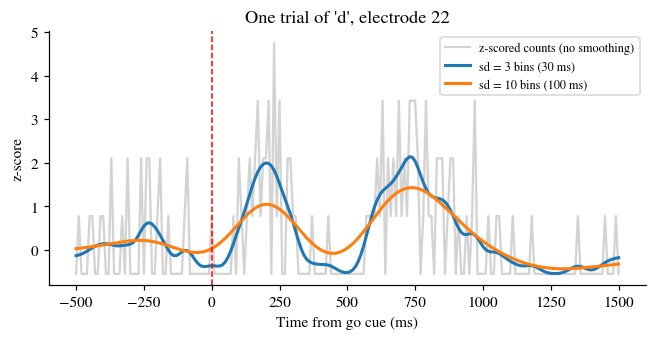

In [10]:
def gauss_smooth(x, sd_bins, axis):
    """Smooth `x` with a Gaussian of standard deviation `sd_bins` along `axis`.
    Near the edges the kernel is renormalized, so the ends are not pulled towards zero
    (same as gaussSmooth_fast.m from the authors' code)."""
    num = gaussian_filter1d(x, sd_bins, axis=axis, mode="constant", truncate=5)
    den = gaussian_filter1d(np.ones(x.shape[axis]), sd_bins, mode="constant", truncate=5)
    shape = [1] * x.ndim
    shape[axis] = -1
    return num / den.reshape(shape)

trial = z[CHARS.index("d"), 0, :, ELECTRODE]
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(t_ms, trial, color="lightgray", label="z-scored counts (no smoothing)")
ax.plot(t_ms, gauss_smooth(trial, 3, axis=0), lw=2, label="sd = 3 bins (30 ms)")
ax.plot(t_ms, gauss_smooth(trial, 10, axis=0), lw=2, label="sd = 10 bins (100 ms)")
ax.axvline(0, color="r", ls="--", lw=1)
ax.set_xlabel("Time from go cue (ms)")
ax.set_ylabel("z-score")
ax.set_title(f"One trial of 'd', electrode {ELECTRODE}")
ax.legend(fontsize=8)
plt.show()

### 4.3 The whole population at once

Now let's look at **all 192 electrodes**, averaged over trials. Each row of the heatmap is one electrode.
We sort electrodes by *when* they peak for the letter `d`, then keep the **same order** for the other letters.

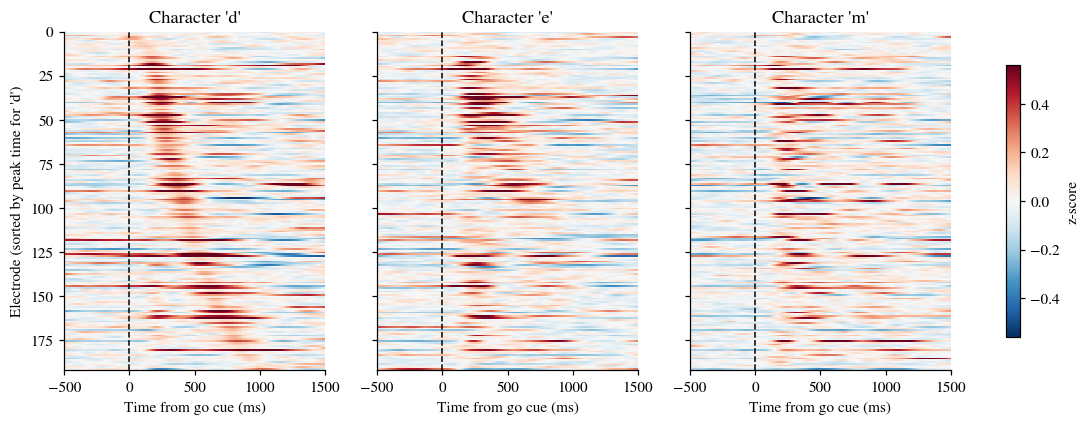

In [11]:
avg_z = gauss_smooth(z.mean(axis=1), 5, axis=1)            # (31 chars, 201 time, 192 electrodes)
order = np.argsort(np.argmax(avg_z[CHARS.index("d")][go_period], axis=0))
vmax = np.percentile(np.abs(avg_z), 99)

fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, c in zip(axes, EXAMPLE_CHARS):
    im = ax.imshow(avg_z[CHARS.index(c)][:, order].T, aspect="auto", cmap="RdBu_r",
                   vmin=-vmax, vmax=vmax, extent=[t_ms[0], t_ms[-1], n_elec, 0], interpolation="none")
    ax.axvline(0, color="k", ls="--", lw=1)
    ax.set_title(f"Character '{SYMBOL[c]}'")
    ax.set_xlabel("Time from go cue (ms)")
axes[0].set_ylabel("Electrode (sorted by peak time for 'd')")
fig.colorbar(im, ax=axes, label="z-score", shrink=0.8)
plt.show()

The sorted order makes a clear sweep for `d`. With the same order, `e` and `m` look different:
**each character drives a different pattern of activity across the population.** That is what lets us decode them.

## 5. Principal Component Analysis (PCA)

192 electrodes are a lot to look at, and many of them carry overlapping (correlated) information.
**PCA** finds a few new axes, the *principal components (PCs)*, that capture most of the variation in the data.
Each PC is a weighted combination of all 192 electrodes.

Following the paper:
- We use the time window **+90 ms to +1500 ms** after the go cue (142 bins), when T5 is writing.
- We **fit** PCA on the *trial-averaged* activity of all 31 characters, which is much less noisy than single trials.
- We then **project** every single trial onto the top PCs.

Top 15 PCs explain 81.8% of the variance of the trial-averaged activity


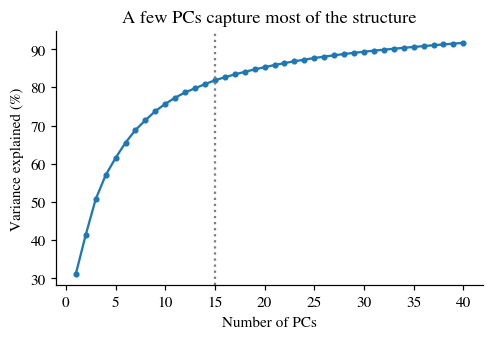

In [12]:
WIN = slice(59, None)                 # bins 59..200  ->  +90 ms .. +1500 ms
t_win = t_ms[WIN]
n_win = len(t_win)

# Fit: rows = (character, time) samples, columns = electrodes
avg_win = avg_z[:, WIN, :]                                   # (31, 142, 192)
pca = PCA().fit(avg_win.reshape(-1, n_elec))

cum_var = np.cumsum(pca.explained_variance_ratio_) * 100
N_PCS = 15
print(f"Top {N_PCS} PCs explain {cum_var[N_PCS - 1]:.1f}% of the variance of the trial-averaged activity")

fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(np.arange(1, 41), cum_var[:40], "o-", ms=3)
ax.axvline(N_PCS, color="gray", ls=":")
ax.set_xlabel("Number of PCs")
ax.set_ylabel("Variance explained (%)")
ax.set_title("A few PCs capture most of the structure")
plt.show()

In [13]:
def project_trials(cube, sd_bins=3):
    """Smooth single trials, keep the analysis window and project onto the top N_PCS PCs.
    cube: (31, 27, 201, 192)  ->  returns (31, 27, 142, N_PCS)"""
    smoothed = gauss_smooth(cube, sd_bins, axis=2)[:, :, WIN, :]
    pcs = pca.transform(smoothed.reshape(-1, n_elec))[:, :N_PCS]
    return pcs.reshape(n_chars, n_trials, n_win, N_PCS)

pcs_unwarped = project_trials(z)
print("pcs_unwarped.shape =", pcs_unwarped.shape, " (characters, trials, time, PCs)")

pcs_unwarped.shape = (31, 27, 142, 15)  (characters, trials, time, PCs)


Let's look at the top 3 PCs for every single trial of `d`, `e` and `m`. Each row in a heatmap is one trial.

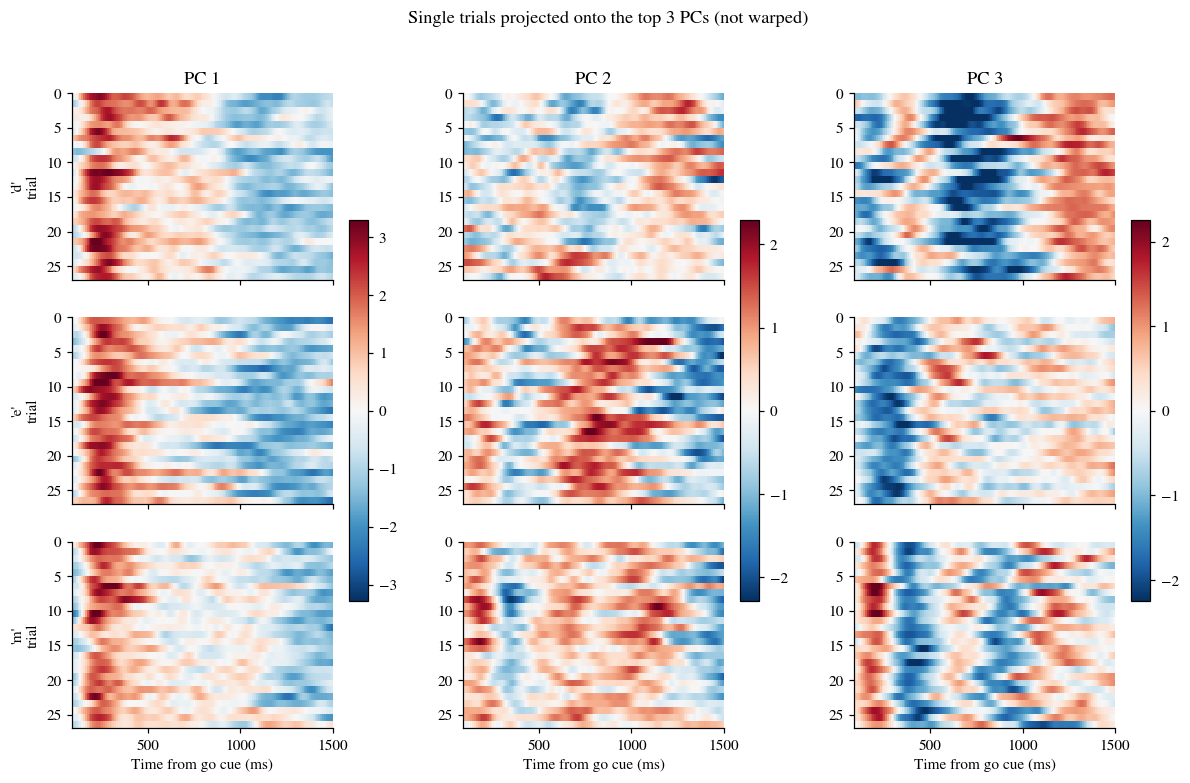

In [14]:
def plot_pc_heatmaps(pcs, chars, title):
    fig, axes = plt.subplots(len(chars), 3, figsize=(13, 2.5*len(chars)), sharex=True)
    for col in range(3):
        vmax = np.percentile(np.abs(pcs[..., col]), 99)
        for row, c in enumerate(chars):
            ax = axes[row, col]
            im = ax.imshow(pcs[CHARS.index(c), :, :, col], aspect="auto", cmap="RdBu_r",
                           vmin=-vmax, vmax=vmax, extent=[t_win[0], t_win[-1], n_trials, 0], interpolation="none")
            if row == 0:
                ax.set_title(f"PC {col + 1}")
            if col == 0:
                ax.set_ylabel(f"'{SYMBOL[c]}'\ntrial")
            if row == len(chars) - 1:
                ax.set_xlabel("Time from go cue (ms)")
        fig.colorbar(im, ax=axes[:, col], shrink=0.6)
    fig.suptitle(title)
    plt.show()

plot_pc_heatmaps(pcs_unwarped, EXAMPLE_CHARS, "Single trials projected onto the top 3 PCs (not warped)")

There is a consistent pattern for each character, but it is **jittered in time** from trial to trial.
Sometimes T5 wrote a little faster, sometimes a little slower. That timing variability blurs trial averages
and makes trials of the same letter look less alike. The next section fixes this.

## 6. Time warping

**Time warping** stretches and compresses each trial in time so that the same events line up across trials.
Think of aligning several recordings of someone saying the same word at different speeds.

The authors used *time-warped PCA* ([Williams et al., 2020](https://doi.org/10.1016/j.neuron.2019.10.020)).
It learns a smooth warping function for every trial. The file `t5.2019.05.08_warpedCubes.mat` contains:

| Variable | Shape | Meaning |
|---|---|---|
| `<char>` | (27, 201, 192) | The z-scored trials of that character **after warping** (same z-scoring as Section 4.1) |
| `<char>_T` | (201, 27) | The learned **warping function** for each of the 27 trials |

Warping can shift data past the ends of the 201-bin window. Those bins have no data and are stored as `NaN`.
We set them to 0, which is the average of z-scored data.

In [15]:
wdat = scipy.io.loadmat(DATA_DIR / "t5.2019.05.08_warpedCubes.mat")

warped = np.stack([wdat[c] for c in CHARS]).astype(float)       # (31, 27, 201, 192)
warp_fns = np.stack([wdat[c + "_T"] for c in CHARS])              # (31, 201, 27)
print("warped.shape   =", warped.shape)
print("warp_fns.shape =", warp_fns.shape)
print(f"Fraction of NaN values: {np.isnan(warped).mean():.1%}")
warped = np.nan_to_num(warped, nan=0.0)

warped.shape   = (31, 27, 201, 192)
warp_fns.shape = (31, 201, 27)
Fraction of NaN values: 4.9%


### 6.1 What do the warping functions look like?

Each line is one trial. A line on the diagonal means "no warping". Bending away from the diagonal means that part of the trial was sped up or slowed down.

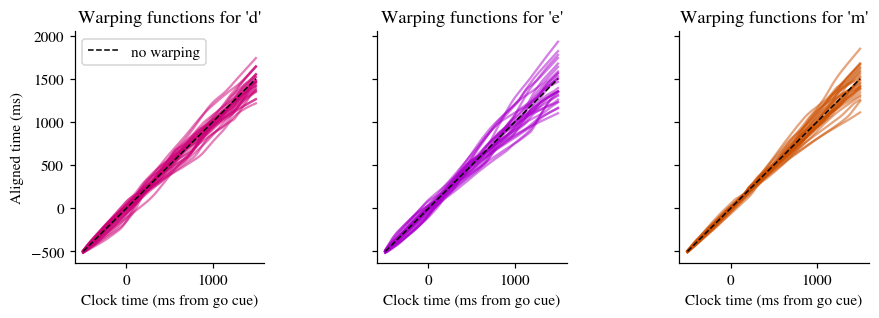

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(9, 3), sharey=True)
for ax, c in zip(axes, EXAMPLE_CHARS):
    fns = warp_fns[CHARS.index(c)]                               # (201 bins, 27 trials)
    ax.plot(t_ms, (fns - GO_IDX)*BIN_MS, color=COLORS[CHARS.index(c)], alpha=0.5)
    ax.plot(t_ms, t_ms, "k--", lw=1, label="no warping")
    ax.set_aspect("equal")
    ax.set_title(f"Warping functions for '{SYMBOL[c]}'")
    ax.set_xlabel("Clock time (ms from go cue)")
axes[0].set_ylabel("Aligned time (ms)")
axes[0].legend()
plt.tight_layout()
plt.show()

### 6.2 Before vs. after warping

We project the warped trials onto **the same PCs** as before and compare single trials of `m`.
Thin lines are single trials and the thick line is their average.

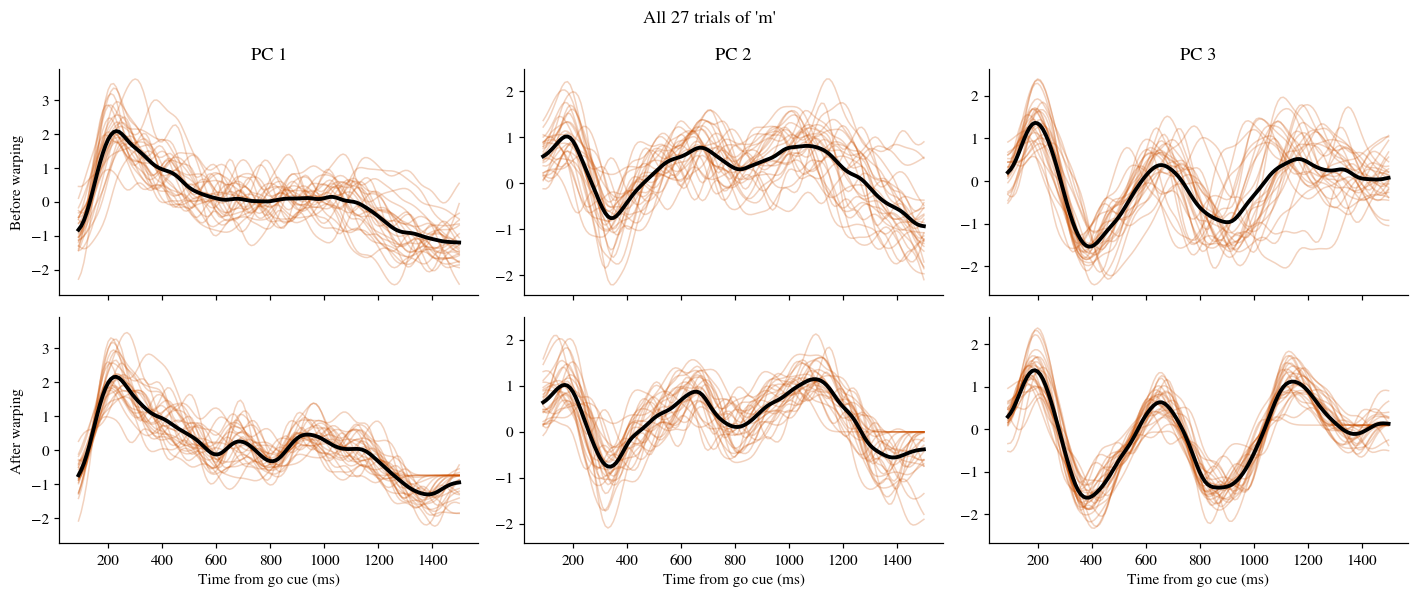

Trial consistency, all characters: before warping = 0.48, after warping = 0.64


In [17]:
pcs_warped = project_trials(warped)

char = "m"
ci = CHARS.index(char)
fig, axes = plt.subplots(2, 3, figsize=(13, 5.5), sharex=True, sharey="col")
for col in range(3):
    for row, (pcs, label) in enumerate([(pcs_unwarped, "Before warping"), (pcs_warped, "After warping")]):
        ax = axes[row, col]
        ax.plot(t_win, pcs[ci, :, :, col].T, color=COLORS[ci], alpha=0.25, lw=1)
        ax.plot(t_win, pcs[ci, :, :, col].mean(axis=0), color="black", lw=2.5)
        if row == 0:
            ax.set_title(f"PC {col + 1}")
        if col == 0:
            ax.set_ylabel(label)
        if row == 1:
            ax.set_xlabel("Time from go cue (ms)")
fig.suptitle(f"All 27 trials of '{SYMBOL[char]}'")
plt.tight_layout()
plt.show()

def trial_consistency(pcs):
    """Fraction of single-trial variance explained by the trial average (1 = all trials identical)."""
    residual = pcs - pcs.mean(axis=1, keepdims=True)
    centered = pcs - pcs.mean(axis=(1, 2), keepdims=True)
    return 1 - (residual ** 2).sum() / (centered ** 2).sum()

print(f"Trial consistency, all characters: before warping = {trial_consistency(pcs_unwarped):.2f}, "
      f"after warping = {trial_consistency(pcs_warped):.2f}")

After warping, the trials line up much better, so the trial average is sharper and more representative.

> **Try it:** Repeat the comparison for another character, e.g. `char = "z"`, or try a higher PC.

## 7. Neural trajectories

At every moment the population activity is a point in a high-dimensional space: one axis per electrode, or one axis per PC.
As time passes the point moves, tracing out a **neural trajectory**. Plotting the trajectory in the top 2–3 PCs shows *how*
the population activity evolves while T5 writes a character.

We use the **trial-averaged, warped** data, since it is the cleanest. PC 1 is mostly a large "movement is starting" signal
that looks similar for every character, so the more character-specific shapes often appear in PCs 2 and 3.

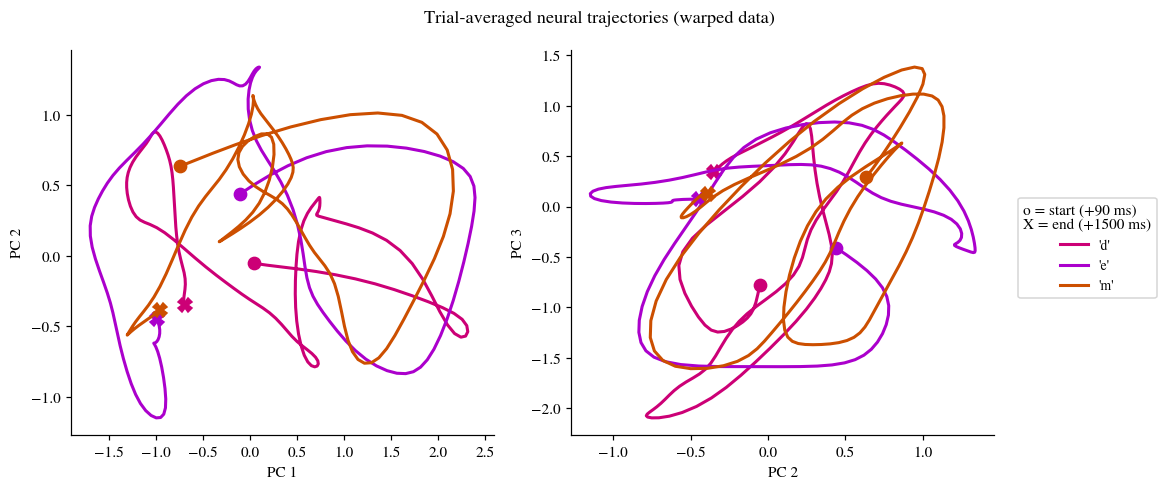

In [18]:
TRAJ_CHARS = ["d", "e", "m"]
avg_warped = pcs_warped.mean(axis=1)            # (31 chars, 142 time, 15 PCs)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (i, j) in zip(axes, [(0, 1), (1, 2)]):
    for c in TRAJ_CHARS:
        traj = avg_warped[CHARS.index(c)]
        color = COLORS[CHARS.index(c)]
        ax.plot(traj[:, i], traj[:, j], color=color, lw=2, label=f"'{SYMBOL[c]}'")
        ax.plot(traj[0, i], traj[0, j], "o", color=color, ms=8)       # start
        ax.plot(traj[-1, i], traj[-1, j], "X", color=color, ms=9)     # end
    ax.set_xlabel(f"PC {i + 1}")
    ax.set_ylabel(f"PC {j + 1}")
fig.suptitle("Trial-averaged neural trajectories (warped data)")
plt.tight_layout(rect=[0, 0, 0.84, 1])                 # leave room on the right for the legend
handles, legend_labels = axes[0].get_legend_handles_labels()
fig.legend(handles, legend_labels, title="o = start (+90 ms)\nX = end (+1500 ms)",
           loc="center left", bbox_to_anchor=(0.84, 0.5), fontsize=9)
plt.show()

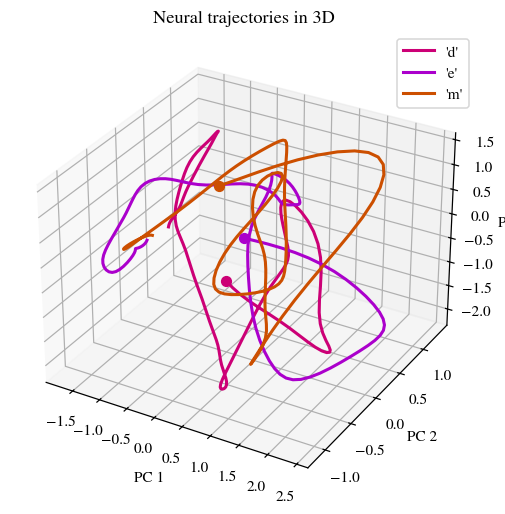

In [19]:
fig = plt.figure(figsize=(6, 5.5))
ax = fig.add_subplot(projection="3d")
for c in TRAJ_CHARS:
    traj = avg_warped[CHARS.index(c)]
    color = COLORS[CHARS.index(c)]
    ax.plot(traj[:, 0], traj[:, 1], traj[:, 2], color=color, lw=2, label=f"'{SYMBOL[c]}'")
    ax.scatter(*traj[0, :3], color=color, s=40)
ax.set_xlabel("PC 1")
ax.set_ylabel("PC 2")
ax.set_zlabel("PC 3")
ax.set_title("Neural trajectories in 3D")
ax.legend()
plt.show()

Different characters take different paths through neural state space. Would you expect characters with
similar pen strokes (e.g. `a` and `d`, which both start with a circle) to follow similar paths?

> **Try it:** Set `TRAJ_CHARS = ["a", "d", "o"]` or `["l", "t", "i"]`. Which characters have similar trajectories? Does that match how they are written?

> **Try it:** Change which of the three PCs you visualize, change the angle of view in the 3D plot and and see if any structures are present.

## 8. A map of all characters with t-SNE

Can we see all **837 trials** (31 characters × 27) at once? Each trial is a 142 × 15 = 2130-dimensional point,
far too many dimensions to plot. **t-SNE** (t-distributed Stochastic Neighbor Embedding) squeezes the data down to 2-D:

1. It measures how *similar* every pair of trials is in the original high-dimensional space.
2. It places points on a 2-D map so that trials that were similar end up close together.
3. The map is found by gradient descent from a random start, so **every run gives a slightly different picture**
   (the `random_state` argument fixes the randomness).

t-SNE keeps *neighbourhoods* (which trials are close to each other). Distances between far-apart clusters,
and cluster sizes, are not meaningful.

### 8.1 A distance that ignores writing speed

t-SNE needs a way to measure the **distance** between two trials. The ordinary (Euclidean) distance compares the trials
bin by bin. If T5 wrote the same letter a bit faster on one trial, the two trials look far apart.

The paper uses a **time-warp distance** instead. We stretch or squeeze trial 1 by a factor α (between 0.7 and 1.42),
compare it to trial 2 over their overlapping time bins, and keep the **smallest** distance over all α.
Two trials of the same letter written at different speeds are then still close.

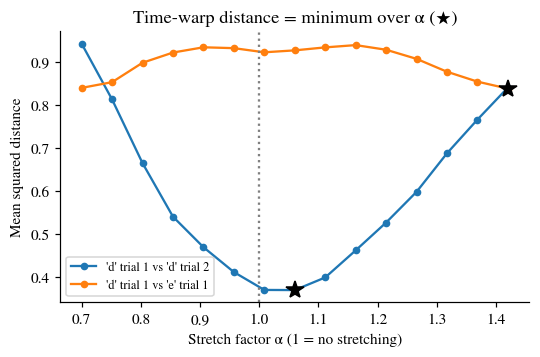

In [20]:
ALPHAS = np.linspace(0.7, 1.42, 15)      # stretch factors used in the paper

def stretch(trials, alpha):
    """Linearly resample the time axis (axis 1) of `trials` to int(alpha * T) bins."""
    T = trials.shape[1]
    new_T = int(alpha * T)
    pos = np.linspace(0, T - 1, new_T)                  # where to sample the original trial
    lo = np.floor(pos).astype(int)
    hi = np.minimum(lo + 1, T - 1)
    frac = (pos - lo)[None, :, None]
    return trials[:, lo] * (1 - frac) + trials[:, hi] * frac

# Example: distance between two trials as a function of alpha
x_d0, x_d1, x_e0 = pcs_unwarped[CHARS.index("d"), 0], pcs_unwarped[CHARS.index("d"), 1], pcs_unwarped[CHARS.index("e"), 0]

def dist_vs_alpha(x1, x2):
    out = []
    for a in ALPHAS:
        x1s = stretch(x1[None], a)[0]
        L = min(len(x1s), len(x2))                       # compare only overlapping bins
        out.append(np.mean((x1s[:L] - x2[:L]) ** 2))
    return np.array(out)

fig, ax = plt.subplots(figsize=(5.5, 3.2))
for x2, label in [(x_d1, "'d' trial 1 vs 'd' trial 2"), (x_e0, "'d' trial 1 vs 'e' trial 1")]:
    curve = dist_vs_alpha(x_d0, x2)
    ax.plot(ALPHAS, curve, "o-", ms=4, label=label)
    ax.plot(ALPHAS[curve.argmin()], curve.min(), "k*", ms=12)
ax.axvline(1, color="gray", ls=":")
ax.set_xlabel("Stretch factor α (1 = no stretching)")
ax.set_ylabel("Mean squared distance")
ax.set_title("Time-warp distance = minimum over α (★)")
ax.legend(fontsize=8)
plt.show()

Computing this for every pair of the 837 trials one pair at a time is slow (~20 minutes in pure Python).
Instead, we stretch **all** trials at once for each α and compute all pairwise distances with one matrix operation.
This takes only a few seconds.

In [21]:
def warp_distance_matrix(X, alphas=ALPHAS):
    """Pairwise time-warp distances between trials.
    X: (n_trials, T, n_dims)  ->  (n_trials, n_trials) matrix of mean squared distances."""
    n, T, dims = X.shape
    D = np.full((n, n), np.inf)
    for a in alphas:
        Xs = stretch(X, a)
        L = min(Xs.shape[1], T)
        D_a = cdist(Xs[:, :L].reshape(n, -1), X[:, :L].reshape(n, -1), "sqeuclidean") / (L * dims)
        D = np.minimum(D, D_a)                          # keep the best alpha for every pair
    return np.minimum(D, D.T)                           # make it symmetric

# One row per trial, as in the paper: single trials, NOT warped, top 15 PCs
X_trials = pcs_unwarped.reshape(n_chars * n_trials, n_win, N_PCS)
labels = np.repeat(np.arange(n_chars), n_trials)       # character index of every row

D_warp = warp_distance_matrix(X_trials)
D_eucl = cdist(X_trials.reshape(len(X_trials), -1), X_trials.reshape(len(X_trials), -1), "sqeuclidean") / (n_win * N_PCS)
print("Distance matrices:", D_warp.shape)

Distance matrices: (837, 837)


### 8.2 Run t-SNE

We give t-SNE our pre-computed distances (`metric="precomputed"`). We use the square root of the mean squared distance
because scikit-learn squares the distances internally. For comparison, we also run it with the ordinary Euclidean distance.

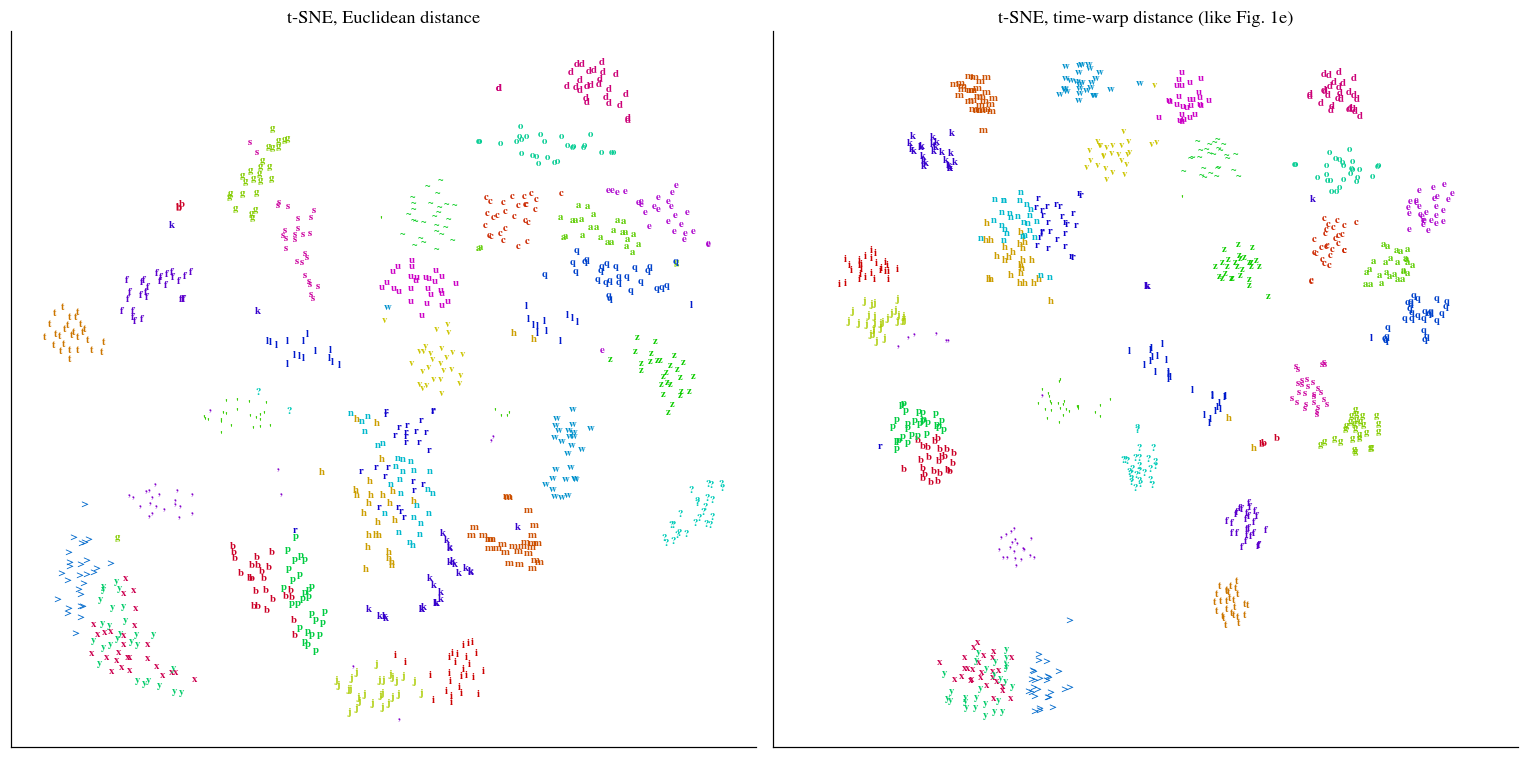

In [22]:
def run_tsne(D, seed=0):
    tsne = TSNE(n_components=2, perplexity=40, metric="precomputed", init="random", random_state=seed)
    return tsne.fit_transform(np.sqrt(D))

def plot_tsne(ax, Y, title):
    """Draw every trial as its character, coloured like Fig. 1e of the paper."""
    ax.scatter(Y[:, 0], Y[:, 1], s=0)                    # invisible, just sets the axis limits
    for (x, y), lab in zip(Y, labels):
        ax.text(x, y, SYMBOL[CHARS[lab]], color=COLORS[lab], fontsize=7, fontweight="bold",
                ha="center", va="center")
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_aspect("equal", adjustable="datalim")

Y_warp = run_tsne(D_warp)
Y_eucl = run_tsne(D_eucl)

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
plot_tsne(axes[0], Y_eucl, "t-SNE, Euclidean distance")
plot_tsne(axes[1], Y_warp, "t-SNE, time-warp distance (like Fig. 1e)")
plt.tight_layout()
plt.show()

Each of the 837 trials is drawn as the character T5 was writing. Trials of the same character form tight,
well-separated clusters. Some clusters sit next to each other because the characters are written similarly
(look for groups like `h`/`n`/`r`, `x`/`y` or `b`/`p`).

> **Try it:** Change `seed` in `run_tsne(D_warp, seed=1)`. The layout changes, but do the clusters stay the same? Try a different `perplexity`, too.

## 9. Decoding: which character was T5 writing?

If trials of the same character cluster together, we can **decode** a new trial by looking at its nearest neighbours.
A **k-nearest-neighbours (k-NN) classifier** does exactly that:

1. Take one trial and hide its label.
2. Find the `k = 10` most similar other trials, using our distance matrix.
3. Predict the most common character among those neighbours.
4. Repeat for every trial (*leave-one-out* cross-validation) and count how often we are right.

With 31 characters, guessing at random would be right only 1/31 ≈ **3%** of the time.

In [23]:
def knn_predict(D, k=10):
    """Leave-one-out k-NN predictions from a distance matrix."""
    D = D.copy()
    np.fill_diagonal(D, np.inf)                           # a trial may not use itself
    neighbours = np.argsort(D, axis=1)[:, :k]
    return np.array([np.bincount(labels[nb], minlength=n_chars).argmax() for nb in neighbours])

pred_warp = knn_predict(D_warp)
pred_eucl = knn_predict(D_eucl)
print(f"Chance level:                   {1 / n_chars:.1%}")
print(f"k-NN accuracy, Euclidean:       {np.mean(pred_eucl == labels):.1%}")
print(f"k-NN accuracy, time-warp dist.: {np.mean(pred_warp == labels):.1%}   (paper: ~94%)")

Chance level:                   3.2%
k-NN accuracy, Euclidean:       89.0%
k-NN accuracy, time-warp dist.: 93.7%   (paper: ~94%)


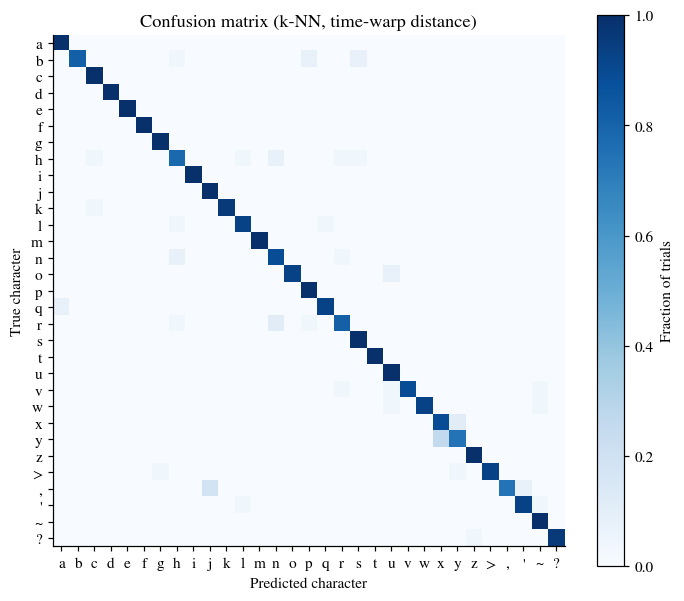

Most common mistakes:
  'y' decoded as 'x': 7 times
  ',' decoded as 'j': 5 times
  'r' decoded as 'n': 3 times
  'x' decoded as 'y': 3 times
  'b' decoded as 'p': 2 times


In [24]:
confusion = np.zeros((n_chars, n_chars))
for true, guess in zip(labels, pred_warp):
    confusion[true, guess] += 1

fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(confusion / n_trials, cmap="Blues", vmin=0, vmax=1)
ticks = [SYMBOL[c] for c in CHARS]
ax.set_xticks(range(n_chars))
ax.set_xticklabels(ticks)
ax.set_yticks(range(n_chars))
ax.set_yticklabels(ticks)
ax.set_xlabel("Predicted character")
ax.set_ylabel("True character")
ax.set_title("Confusion matrix (k-NN, time-warp distance)")
fig.colorbar(im, label="Fraction of trials")
plt.show()

off_diag = confusion.copy()
np.fill_diagonal(off_diag, 0)
print("Most common mistakes:")
for idx in np.argsort(off_diag, axis=None)[::-1][:5]:
    t, p = np.unravel_index(idx, off_diag.shape)
    print(f"  '{SYMBOL[CHARS[t]]}' decoded as '{SYMBOL[CHARS[p]]}': {int(off_diag[t, p])} times")

Even this very simple decoder recognizes the attempted character over 90% of the time, from neural activity alone.
The paper's full system goes much further: a recurrent neural network decodes *continuous* sentences in real time,
and a language model then corrects the remaining errors.

## 10. Summary

- The data are **binned threshold crossings** (10 ms bins) from **192 electrodes** in the hand area of motor cortex,
  recorded while T5 attempted to write 31 characters, 27 times each.
- Preprocessing (**block-wise z-scoring** and **Gaussian smoothing**) removes drift, puts electrodes on a common scale and reduces noise.
- **PCA** shows that most of the structure lives in a few dimensions.
- **Time warping** corrects for trial-to-trial differences in writing speed.
- **Neural trajectories** and **t-SNE** show that each character has its own distinct neural signature.
- A simple **k-NN decoder** already identifies the character about 94% of the time.

### Exercises
1. **Smoothing trade-off:** Re-run Section 5 and the decoder with a different smoothing width in `project_trials(z, sd_bins=...)`. How does accuracy change with `sd_bins = 1` or `sd_bins = 10`?
2. **How many PCs?** Change `N_PCS` to 3, 5 or 30 and re-run Sections 5, 8 and 9. How does decoding accuracy depend on the number of PCs?
3. **Warped data for decoding:** Decode using `pcs_warped` instead of `pcs_unwarped` with plain Euclidean distance. Is it as good as the time-warp distance? *(Careful: the warping was fit using all trials, so this is a slightly optimistic test.)*
4. **Less data:** How does accuracy change if you only use the first 10 trials of each character?

### Further reading

- Willett et al. (2021). [High-performance brain-to-text communication via handwriting](https://doi.org/10.1038/s41586-021-03506-2). *Nature*.
    - The dataset on [Dryad](https://doi.org/10.5061/dryad.wh70rxwmv) and the authors' code on [GitHub](https://github.com/fwillett/handwritingBCI).